# 📰 Fake News Detection - Data Preprocessing Pipeline
### Dataset: GossipCop Fake News (`gossipcop_fake.csv`)
This notebook provides an end-to-end data preprocessing and feature engineering pipeline for Fake News Detection using Natural Language Processing (NLP).

## Step 1: Install & Import Libraries

In [1]:
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urlparse

# NLP Libraries
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from wordcloud import WordCloud

# Download all required NLTK datasets
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

print('✅ All libraries imported and NLTK resources downloaded successfully!')

✅ All libraries imported and NLTK resources downloaded successfully!


## Step 2: Load the Dataset & Inspect Structure

In [2]:
# Path to dataset
file_path = r'C:\Users\SANTOSH REDDY\Downloads\Telegram Desktop\gossipcop_fake.csv'

# Load CSV into pandas DataFrame
df = pd.read_csv(file_path, encoding='utf-8', on_bad_lines='skip')

print(f'📊 Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n')
display(df.head())

📊 Dataset Dimensions: 5335 rows, 4 columns



,id,news_url,title,tweet_ids
0,gossipcop-2493749932,www.dailymail.co.uk/tvshowbiz/article-5874213/...,Did Miley Cyrus and Liam Hemsworth secretly ge...,284329075902926848\t284332744559968256\t284335...
1,gossipcop-4580247171,hollywoodlife.com/2018/05/05/paris-jackson-car...,Paris Jackson & Cara Delevingne Enjoy Night Ou...,992895508267130880\t992897935418503169\t992899...
2,gossipcop-941805037,variety.com/2017/biz/news/tax-march-donald-tru...,Celebrities Join Tax March in Protest of Donal...,853359353532829696\t853359576543920128\t853359...
3,gossipcop-2547891536,www.dailymail.co.uk/femail/article-3499192/Do-...,Cindy Crawford's daughter Kaia Gerber wears a ...,988821905196158981\t988824206556172288\t988825...
4,gossipcop-5476631226,variety.com/2018/film/news/list-2018-oscar-nom...,Full List of 2018 Oscar Nominations – Variety,955792793632432131\t955795063925301249\t955798...


## Step 3: Check Data Types, Missing Values & Duplicates

In [3]:
print('--- Column Information ---')
df.info()

print('\n--- Missing Values Count ---')
print(df.isnull().sum())

print('\n--- Duplicate Titles ---')
dup_count = df.duplicated(subset=['title']).sum()
print(f'Number of duplicate titles: {dup_count}')

--- Column Information ---
<class 'pandas.DataFrame'>
RangeIndex: 5335 entries, 0 to 5334
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   id         5335 non-null   str  
 1   news_url   5067 non-null   str  
 2   title      5323 non-null   str  
 3   tweet_ids  5135 non-null   str  
dtypes: str(4)
memory usage: 166.8 KB

--- Missing Values Count ---
id             0
news_url     268
title         12
tweet_ids    200
dtype: int64

--- Duplicate Titles ---
Number of duplicate titles: 438


## Step 4: Handle Missing Values, Deduplicate & Add Target Label
Every sample in `gossipcop_fake.csv` represents Fake News, so we assign `label = 1`.

In [4]:
# 1. Drop rows with null titles
df = df.dropna(subset=['title']).copy()

# 2. Remove duplicate titles
df = df.drop_duplicates(subset=['title']).reset_index(drop=True)

# 3. Add target label (1 = Fake)
df['label'] = 1

print(f'✅ Cleaned rows count: {df.shape[0]}')
display(df[['id', 'title', 'label']].head())

✅ Cleaned rows count: 4896


,id,title,label
0,gossipcop-2493749932,Did Miley Cyrus and Liam Hemsworth secretly ge...,1
1,gossipcop-4580247171,Paris Jackson & Cara Delevingne Enjoy Night Ou...,1
2,gossipcop-941805037,Celebrities Join Tax March in Protest of Donal...,1
3,gossipcop-2547891536,Cindy Crawford's daughter Kaia Gerber wears a ...,1
4,gossipcop-5476631226,Full List of 2018 Oscar Nominations – Variety,1


## Step 5: Feature Engineering (Social & Metadata Features)
Extract social propagation count (tweet count), source domain, and text lengths.

In [5]:
# 1. Tweet propagation count
def count_tweets(tweet_str):
    if pd.isna(tweet_str) or not str(tweet_str).strip():
        return 0
    return len(str(tweet_str).strip().split())

df['tweet_count'] = df['tweet_ids'].apply(count_tweets)

# 2. Source domain extraction
def extract_domain(url):
    if pd.isna(url) or not str(url).strip():
        return 'unknown'
    try:
        domain = urlparse(str(url)).netloc
        return domain.replace('www.', '') if domain else str(url).split('/')[0]
    except:
        return 'unknown'

df['domain'] = df['news_url'].apply(extract_domain)

# 3. Character & Word Count
df['char_count'] = df['title'].astype(str).apply(len)
df['word_count'] = df['title'].astype(str).apply(lambda x: len(x.split()))

display(df[['title', 'domain', 'tweet_count', 'word_count', 'label']].head())

,title,domain,tweet_count,word_count,label
0,Did Miley Cyrus and Liam Hemsworth secretly ge...,www.dailymail.co.uk,97,9,1
1,Paris Jackson & Cara Delevingne Enjoy Night Ou...,hollywoodlife.com,15,15,1
2,Celebrities Join Tax March in Protest of Donal...,variety.com,86,9,1
3,Cindy Crawford's daughter Kaia Gerber wears a ...,www.dailymail.co.uk,14,13,1
4,Full List of 2018 Oscar Nominations – Variety,variety.com,66,8,1


## Step 6: Text Preprocessing & NLP Cleaning Pipeline
- Lowercasing
- Removing URLs & HTML tags
- Removing special characters & numbers
- Tokenization & Stopwords removal
- Lemmatization

In [6]:
# Ensure all NLTK resources are available
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def clean_text(text):
    if not isinstance(text, str):
        return ''
    
    # 1. Lowercase
    text = text.lower()
    
    # 2. Remove URLs and HTML tags
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'<.*?>+', '', text)
    
    # 3. Remove punctuation, numbers, and special characters
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    
    # 4. Tokenize
    try:
        tokens = word_tokenize(text)
    except Exception:
        tokens = text.split()
    
    # 5. Remove stopwords and lemmatize
    cleaned_tokens = [
        lemmatizer.lemmatize(w) 
        for w in tokens 
        if w not in stop_words and len(w) > 2
    ]
    
    return ' '.join(cleaned_tokens)

print('Cleaning headlines... Please wait...')
df['clean_title'] = df['title'].apply(clean_text)
print('✅ Text cleaning complete!\n')

# Display comparison
for i in range(3):
    print(f'Original: {df["title"].iloc[i]}')
    print(f'Cleaned:  {df["clean_title"].iloc[i]}\n')

Cleaning headlines... Please wait...
✅ Text cleaning complete!

Original: Did Miley Cyrus and Liam Hemsworth secretly get married?
Cleaned:  miley cyrus liam hemsworth secretly get married

Original: Paris Jackson & Cara Delevingne Enjoy Night Out In Matching Outfits: They Have ‘Amazing Chemistry’
Cleaned:  paris jackson cara delevingne enjoy night matching outfit amazing chemistry

Original: Celebrities Join Tax March in Protest of Donald Trump
Cleaned:  celebrity join tax march protest donald trump



## Step 7: Exploratory Data Analysis & WordCloud

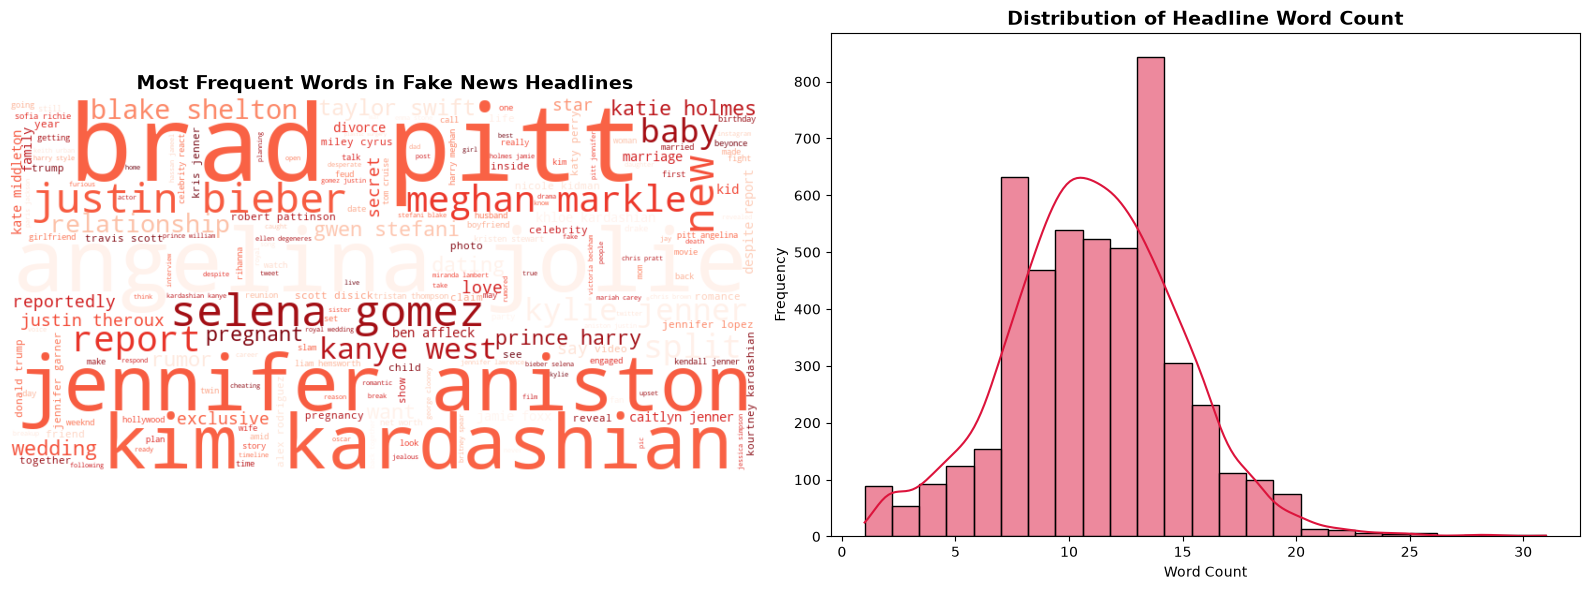

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. WordCloud of most frequent terms
all_words = ' '.join(df['clean_title'])
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='Reds').generate(all_words)
axes[0].imshow(wordcloud, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title('Most Frequent Words in Fake News Headlines', fontsize=14, fontweight='bold')

# 2. Distribution of headline word count
sns.histplot(df['word_count'], bins=25, kde=True, ax=axes[1], color='crimson')
axes[1].set_title('Distribution of Headline Word Count', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

## Step 8: TF-IDF Vectorization (ML Feature Matrix)

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize TF-IDF
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), sublinear_tf=True)
X_tfidf = tfidf.fit_transform(df['clean_title'])

print(f'TF-IDF Matrix Shape: {X_tfidf.shape}')
print('Sample Feature Vocabulary:', tfidf.get_feature_names_out()[:20])

TF-IDF Matrix Shape: (4896, 5000)
Sample Feature Vocabulary: ['aaron' 'aaron carter' 'aaron rodgers' 'abandon' 'abc' 'abdul' 'able'
 'absolute' 'absolutely' 'abuse' 'academy' 'academy award' 'accept'
 'access' 'accident' 'accidentally' 'according' 'according report'
 'account' 'accused']


## Step 9: Save Cleaned Dataset to CSV

In [9]:
output_path = r'C:\Users\SANTOSH REDDY\Downloads\Telegram Desktop\preprocessed_gossipcop_fake.csv'

clean_df = df[['id', 'title', 'clean_title', 'domain', 'tweet_count', 'word_count', 'label']]
clean_df.to_csv(output_path, index=False)

print(f'💾 Cleaned data saved successfully to:\n{output_path}')

💾 Cleaned data saved successfully to:
C:\Users\SANTOSH REDDY\Downloads\Telegram Desktop\preprocessed_gossipcop_fake.csv
